<a href="https://colab.research.google.com/github/Laura-RFLopes/python_sis_26_2/blob/laura_lopes/aula14/laura_lopes_aula_14_exercicio.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:

# API utilizada: WeatherAPI
# Documentação: https://www.weatherapi.com/docs/

from google.colab import userdata
import requests
import pandas as pd

In [3]:
api_key = userdata.get('api_key')

link_api = "https://api.weatherapi.com/v1/current.json"

In [4]:
parametros = {
    "key": api_key,
    "q": "Curitiba",
    "lang": "pt"
}

In [5]:




# Lista com 10 cidades brasileiras
cidades = ["Araucaria", "Curitiba", "Londrina", "Maringa", "Ponta Grossa", "Pinhais", "Manaus", "Recife", "Goiania", "Salvador"]

lista_dados = []

for cidade in cidades:
    parametros = {"key": api_key, "q": cidade, "lang": "pt"}

    try:
        resposta = requests.get(link_api, params=parametros, timeout=10)

        print(f"\nCidade: {cidade}")
        print(f"Status HTTP: {resposta.status_code}")

        resposta.raise_for_status()

        dados = resposta.json()

        print("Chaves principais:", dados.keys())

        lista_dados.append(dados)

    except requests.exceptions.RequestException as erro:
        print(f"Erro ao consultar {cidade}: {erro}")

# Normalizando os sub-dicionários (location e current) em colunas planas
df_clima = pd.json_normalize(lista_dados, sep="_")

# Visualizando as principais colunas geradas
tabela_clima = df_clima[["location_name", "current_temp_c", "current_condition_text"]]

# Renomeando as colunas
tabela_clima.columns = ["Cidade", "Temperatura (°C)", "Condição do tempo"]

# Exibindo a tabela
display(tabela_clima)


Cidade: Araucaria
Status HTTP: 200
Chaves principais: dict_keys(['location', 'current'])

Cidade: Curitiba
Status HTTP: 200
Chaves principais: dict_keys(['location', 'current'])

Cidade: Londrina
Status HTTP: 200
Chaves principais: dict_keys(['location', 'current'])

Cidade: Maringa
Status HTTP: 200
Chaves principais: dict_keys(['location', 'current'])

Cidade: Ponta Grossa
Status HTTP: 200
Chaves principais: dict_keys(['location', 'current'])

Cidade: Pinhais
Status HTTP: 200
Chaves principais: dict_keys(['location', 'current'])

Cidade: Manaus
Status HTTP: 200
Chaves principais: dict_keys(['location', 'current'])

Cidade: Recife
Status HTTP: 200
Chaves principais: dict_keys(['location', 'current'])

Cidade: Goiania
Status HTTP: 200
Chaves principais: dict_keys(['location', 'current'])

Cidade: Salvador
Status HTTP: 200
Chaves principais: dict_keys(['location', 'current'])


,Cidade,Temperatura (°C),Condição do tempo
0,Araucaria,22.3,Chuva passageira fraca
1,Curitiba,22.5,Chuva passageira fraca
2,Londrina,24.1,Chuva passageira fraca
3,Maringa,24.6,Chuva passageira fraca
4,Ponta Grossa,22.7,Chuva passageira fraca
5,Pinhais Novos,10.7,Garoa fraca
6,Manaus,38.6,Parcialmente nublado
7,Recife,29.2,Ensolarado
8,Goiania,27.6,Chuva passageira moderada ou forte
9,Salvador,28.9,Ensolarado


In [6]:
# Normalizando os dicionários em colunas
df_clima = pd.json_normalize(lista_dados, sep="_")

# Selecionando as colunas relevantes
tabela_clima = df_clima[
    [
        "location_name",
        "location_localtime",
        "current_temp_c",
        "current_condition_text",
        "current_humidity",
        "current_wind_kph"
    ]
]

# Renomeando as colunas
tabela_clima.columns = [
    "Cidade",
    "Data/Hora",
    "Temperatura (°C)",
    "Condição do tempo",
    "Umidade (%)",
    "Vento (km/h)"
]

# Exibindo a tabela
display(tabela_clima)

,Cidade,Data/Hora,Temperatura (°C),Condição do tempo,Umidade (%),Vento (km/h)
0,Araucaria,2026-11-25 16:05,22.3,Chuva passageira fraca,92,3.6
1,Curitiba,2026-11-25 16:05,22.5,Chuva passageira fraca,89,3.6
2,Londrina,2026-11-25 16:05,24.1,Chuva passageira fraca,89,3.6
3,Maringa,2026-11-25 16:05,24.6,Chuva passageira fraca,88,3.6
4,Ponta Grossa,2026-11-25 16:05,22.7,Chuva passageira fraca,90,7.6
5,Pinhais Novos,2026-11-25 19:05,10.7,Garoa fraca,88,8.6
6,Manaus,2026-11-25 15:05,38.6,Parcialmente nublado,31,8.6
7,Recife,2026-11-25 16:05,29.2,Ensolarado,63,14.0
8,Goiania,2026-11-25 16:05,27.6,Chuva passageira moderada ou forte,72,3.6
9,Salvador,2026-11-25 16:05,28.9,Ensolarado,67,20.2


In [7]:
# Removendo registros duplicados
tabela_clima = tabela_clima.drop_duplicates()

# Convertendo a coluna de data e hora
tabela_clima["Data/Hora"] = pd.to_datetime(
    tabela_clima["Data/Hora"],
    errors="coerce"
)

# Convertendo as colunas numéricas
tabela_clima["Temperatura (°C)"] = pd.to_numeric(
    tabela_clima["Temperatura (°C)"],
    errors="coerce"
)

tabela_clima["Umidade (%)"] = pd.to_numeric(
    tabela_clima["Umidade (%)"],
    errors="coerce"
)

tabela_clima["Vento (km/h)"] = pd.to_numeric(
    tabela_clima["Vento (km/h)"],
    errors="coerce"
)

# Removendo registros com dados essenciais inválidos
tabela_clima = tabela_clima.dropna(
    subset=["Cidade", "Data/Hora", "Temperatura (°C)"]
)

# Exibindo o resumo estatístico
print("RESUMO ESTATÍSTICO DO CLIMA")
print("--------------------------------")

print(tabela_clima.describe())

# Exibindo a tabela tratada
display(tabela_clima)

RESUMO ESTATÍSTICO DO CLIMA
--------------------------------
                 Data/Hora  Temperatura (°C)  Umidade (%)  Vento (km/h)
count                   10         10.000000    10.000000     10.000000
mean   2026-11-25 16:17:00         25.120000    76.900000      7.700000
min    2026-11-25 15:05:00         10.700000    31.000000      3.600000
25%    2026-11-25 16:05:00         22.550000    68.250000      3.600000
50%    2026-11-25 16:05:00         24.350000    88.000000      5.600000
75%    2026-11-25 16:05:00         28.575000    89.000000      8.600000
max    2026-11-25 19:05:00         38.600000    92.000000     20.200000
std                    NaN          7.060973    19.324423      5.593846


,Cidade,Data/Hora,Temperatura (°C),Condição do tempo,Umidade (%),Vento (km/h)
0,Araucaria,2026-11-25 16:05:00,22.3,Chuva passageira fraca,92,3.6
1,Curitiba,2026-11-25 16:05:00,22.5,Chuva passageira fraca,89,3.6
2,Londrina,2026-11-25 16:05:00,24.1,Chuva passageira fraca,89,3.6
3,Maringa,2026-11-25 16:05:00,24.6,Chuva passageira fraca,88,3.6
4,Ponta Grossa,2026-11-25 16:05:00,22.7,Chuva passageira fraca,90,7.6
5,Pinhais Novos,2026-11-25 19:05:00,10.7,Garoa fraca,88,8.6
6,Manaus,2026-11-25 15:05:00,38.6,Parcialmente nublado,31,8.6
7,Recife,2026-11-25 16:05:00,29.2,Ensolarado,63,14.0
8,Goiania,2026-11-25 16:05:00,27.6,Chuva passageira moderada ou forte,72,3.6
9,Salvador,2026-11-25 16:05:00,28.9,Ensolarado,67,20.2


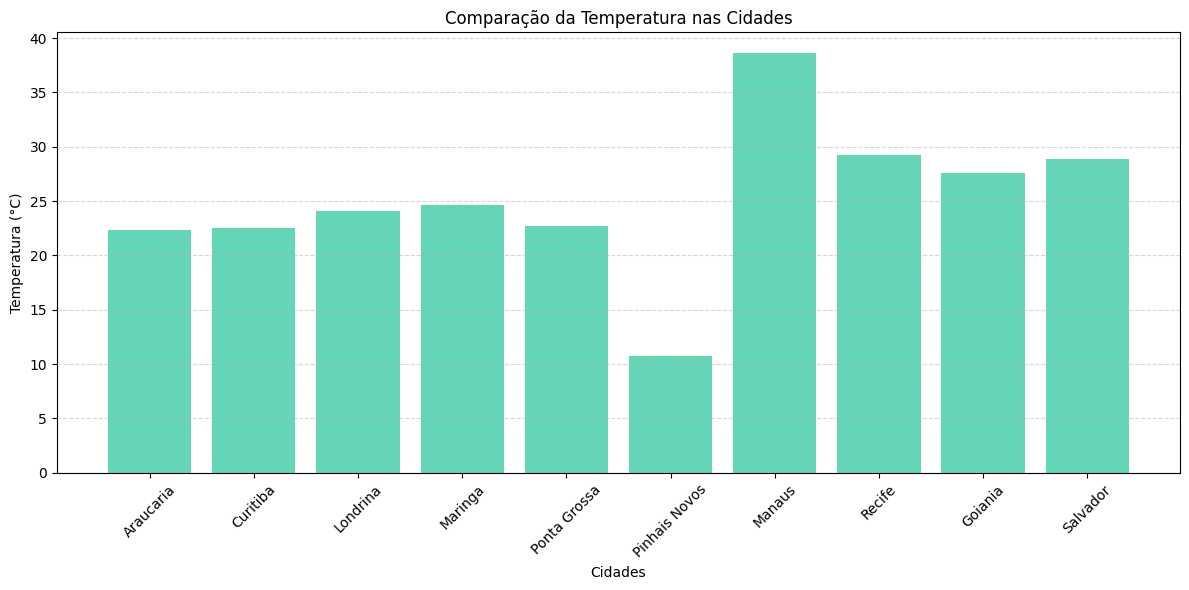

Arquivo relatorio_clima.csv criado com sucesso!


In [12]:
import matplotlib.pyplot as plt

# Criando o gráfico
plt.figure(figsize=(12, 6))

# Comparando as temperaturas das cidades
plt.bar(
    tabela_clima["Cidade"],
    tabela_clima["Temperatura (°C)"],
    color="#64D6B7"
)

# Configurando o gráfico
plt.title("Comparação da Temperatura nas Cidades")
plt.xlabel("Cidades")
plt.ylabel("Temperatura (°C)")
plt.xticks(rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.5)

# Ajustando o layout
plt.tight_layout()

# Exibindo o gráfico
plt.show()

# Exportando os dados tratados para CSV
tabela_clima.to_csv(
    "relatorio_clima.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Arquivo relatorio_clima.csv criado com sucesso!")

In [13]:

# API utilizada: NASA NeoWs
# Documentação: https://api.nasa.gov/

# Importando as bibliotecas
from google.colab import userdata
import requests
import pandas as pd
import matplotlib.pyplot as plt
from datetime import datetime, timedelta

# Etapa 1: Configuração da API.

# Armazenando a chave de forma segura
api_key_nasa = userdata.get('api_key_nasa')

# Definindo o endpoint da API
link_api = "https://api.nasa.gov/neo/rest/v1/feed"

# Definindo o período da consulta (últimos 7 dias)
data_final = datetime.now().date()
data_inicial = data_final - timedelta(days=6)

# Formatando as datas
data_inicio = data_inicial.strftime("%Y-%m-%d")
data_fim = data_final.strftime("%Y-%m-%d")

print("Data inicial:", data_inicio)
print("Data final:", data_fim)


Data inicial: 2026-11-19
Data final: 2026-11-25


In [16]:

# Etapa 2: Consulta à API.

# Definindo os parâmetros da consulta
parametros = {
    "start_date": data_inicio,
    "end_date": data_fim,
    "api_key": api_key_nasa
}

try:

    resposta = requests.get(
        link_api,
        params=parametros,
        timeout=10
    )

    print("Status HTTP:", resposta.status_code)

    resposta.raise_for_status()

    # Convertendo a resposta para JSON
    dados = resposta.json()

    print("Consulta realizada com sucesso!")

except requests.exceptions.RequestException as erro:

    print("Erro na consulta da NASA:", erro)


Status HTTP: 200
Consulta realizada com sucesso!


In [17]:

# Etapa 3: Extração e armazenamento dos dados.

# Lista para armazenar os resultados
lista_asteroides = []

# Verificando os dados recebidos
print("Chaves principais:", dados.keys())

# Percorrendo as datas
for data, asteroides in dados["near_earth_objects"].items():

    # Percorrendo os asteroides de cada data
    for asteroide in asteroides:

        # Obtendo os dados da aproximação
        aproximacao = asteroide["close_approach_data"][0]

        # Armazenando as informações
        registro = {
            "Nome": asteroide["name"],
            "Data": aproximacao["close_approach_date"],
            "Diametro_Max_km": asteroide["estimated_diameter"]["kilometers"]["estimated_diameter_max"],
            "Velocidade_km_h": float(aproximacao["relative_velocity"]["kilometers_per_hour"]),
            "Distancia_km": float(aproximacao["miss_distance"]["kilometers"]),
            "Potencialmente_Perigoso": asteroide["is_potentially_hazardous_asteroid"]
        }

        lista_asteroides.append(registro)

# Exibindo os resultados coletados
for asteroide in lista_asteroides:

    print("\nNome:", asteroide["Nome"])
    print("Data da aproximação:", asteroide["Data"])
    print("Diâmetro máximo:", asteroide["Diametro_Max_km"], "km")
    print("Velocidade:", asteroide["Velocidade_km_h"], "km/h")
    print("Distância:", asteroide["Distancia_km"], "km")
    print("Potencialmente perigoso:", asteroide["Potencialmente_Perigoso"])

print("\nTotal de asteroides encontrados:", len(lista_asteroides))


Chaves principais: dict_keys(['element_count', 'links', 'near_earth_objects'])

Nome: (2004 XK14)
Data da aproximação: 2026-11-19
Diâmetro máximo: 0.1932146172 km
Velocidade: 31401.4613902227 km/h
Distância: 13132346.902443938 km
Potencialmente perigoso: False

Nome: (2014 UO33)
Data da aproximação: 2026-11-19
Diâmetro máximo: 0.2167903661 km
Velocidade: 46744.1236250968 km/h
Distância: 67011350.94967056 km
Potencialmente perigoso: False

Nome: (2015 YQ1)
Data da aproximação: 2026-11-19
Diâmetro máximo: 0.0149293183 km
Velocidade: 33450.1289674422 km/h
Distância: 49038139.479722366 km
Potencialmente perigoso: False

Nome: (2018 NE1)
Data da aproximação: 2026-11-19
Diâmetro máximo: 0.1241766613 km
Velocidade: 47823.508154057 km/h
Distância: 6385660.433397119 km
Potencialmente perigoso: False

Nome: (2018 VS4)
Data da aproximação: 2026-11-19
Diâmetro máximo: 0.0368162863 km
Velocidade: 38583.1612035299 km/h
Distância: 19716349.81676697 km
Potencialmente perigoso: False

Nome: (2019 WL3)


In [18]:

# Etapa 1: Conversão para DataFrame.

# Transformando a lista em DataFrame
df_asteroides = pd.DataFrame(lista_asteroides)

# Selecionando as colunas relevantes
tabela_asteroides = df_asteroides[
    [
        "Nome",
        "Data",
        "Diametro_Max_km",
        "Velocidade_km_h",
        "Distancia_km",
        "Potencialmente_Perigoso"
    ]
]

# Renomeando as colunas
tabela_asteroides.columns = [
    "Nome",
    "Data da aproximação",
    "Diâmetro máximo (km)",
    "Velocidade (km/h)",
    "Distância (km)",
    "Potencialmente perigoso"
]

# Exibindo a tabela
display(tabela_asteroides)


,Nome,Data da aproximação,Diâmetro máximo (km),Velocidade (km/h),Distância (km),Potencialmente perigoso
0,(2004 XK14),2026-11-19,0.193215,31401.461390,1.313235e+07,False
1,(2014 UO33),2026-11-19,0.216790,46744.123625,6.701135e+07,False
2,(2015 YQ1),2026-11-19,0.014929,33450.128967,4.903814e+07,False
3,(2018 NE1),2026-11-19,0.124177,47823.508154,6.385660e+06,False
4,(2018 VS4),2026-11-19,0.036816,38583.161204,1.971635e+07,False
5,(2019 WL3),2026-11-19,0.049436,52749.567135,4.235392e+07,False
6,(2019 XS),2026-11-19,0.101400,66219.748607,3.844308e+07,False
7,(2019 SB6),2026-11-23,0.026184,21375.310113,3.146055e+07,False
8,(2008 GS3),2026-11-22,0.208949,82675.558354,7.397681e+07,False
9,(2010 HG20),2026-11-22,0.311918,37710.518905,1.632617e+07,False


In [19]:

# Etapa 2: Tratamento e tipagem dos dados.

# Removendo registros duplicados
tabela_asteroides = tabela_asteroides.drop_duplicates()

# Convertendo a coluna de data
tabela_asteroides["Data da aproximação"] = pd.to_datetime(
    tabela_asteroides["Data da aproximação"],
    errors="coerce"
)

# Convertendo as colunas numéricas
tabela_asteroides["Diâmetro máximo (km)"] = pd.to_numeric(
    tabela_asteroides["Diâmetro máximo (km)"],
    errors="coerce"
)

tabela_asteroides["Velocidade (km/h)"] = pd.to_numeric(
    tabela_asteroides["Velocidade (km/h)"],
    errors="coerce"
)

tabela_asteroides["Distância (km)"] = pd.to_numeric(
    tabela_asteroides["Distância (km)"],
    errors="coerce"
)

# Exibindo o resumo estatístico
print("RESUMO ESTATÍSTICO DOS ASTEROIDES")
print("--------------------------------")

print(tabela_asteroides.describe())

# Exibindo a tabela tratada
display(tabela_asteroides)


RESUMO ESTATÍSTICO DOS ASTEROIDES
--------------------------------
                 Data da aproximação  Diâmetro máximo (km)  Velocidade (km/h)  \
count                             33             33.000000          33.000000   
mean   2026-11-22 07:16:21.818181888              0.160202       49851.338238   
min              2026-11-19 00:00:00              0.014929        1477.093942   
25%              2026-11-20 00:00:00              0.056760       37710.518905   
50%              2026-11-23 00:00:00              0.131838       49427.925249   
75%              2026-11-25 00:00:00              0.216790       63258.402721   
max              2026-11-25 00:00:00              0.625230       91515.065128   
std                              NaN              0.131031       19755.471902   

       Distância (km)  
count    3.300000e+01  
mean     3.961520e+07  
min      6.385660e+06  
25%      2.089235e+07  
50%      3.844308e+07  
75%      5.828669e+07  
max      7.397681e+07  
std      2.

,Nome,Data da aproximação,Diâmetro máximo (km),Velocidade (km/h),Distância (km),Potencialmente perigoso
0,(2004 XK14),2026-11-19,0.193215,31401.461390,1.313235e+07,False
1,(2014 UO33),2026-11-19,0.216790,46744.123625,6.701135e+07,False
2,(2015 YQ1),2026-11-19,0.014929,33450.128967,4.903814e+07,False
3,(2018 NE1),2026-11-19,0.124177,47823.508154,6.385660e+06,False
4,(2018 VS4),2026-11-19,0.036816,38583.161204,1.971635e+07,False
5,(2019 WL3),2026-11-19,0.049436,52749.567135,4.235392e+07,False
6,(2019 XS),2026-11-19,0.101400,66219.748607,3.844308e+07,False
7,(2019 SB6),2026-11-23,0.026184,21375.310113,3.146055e+07,False
8,(2008 GS3),2026-11-22,0.208949,82675.558354,7.397681e+07,False
9,(2010 HG20),2026-11-22,0.311918,37710.518905,1.632617e+07,False


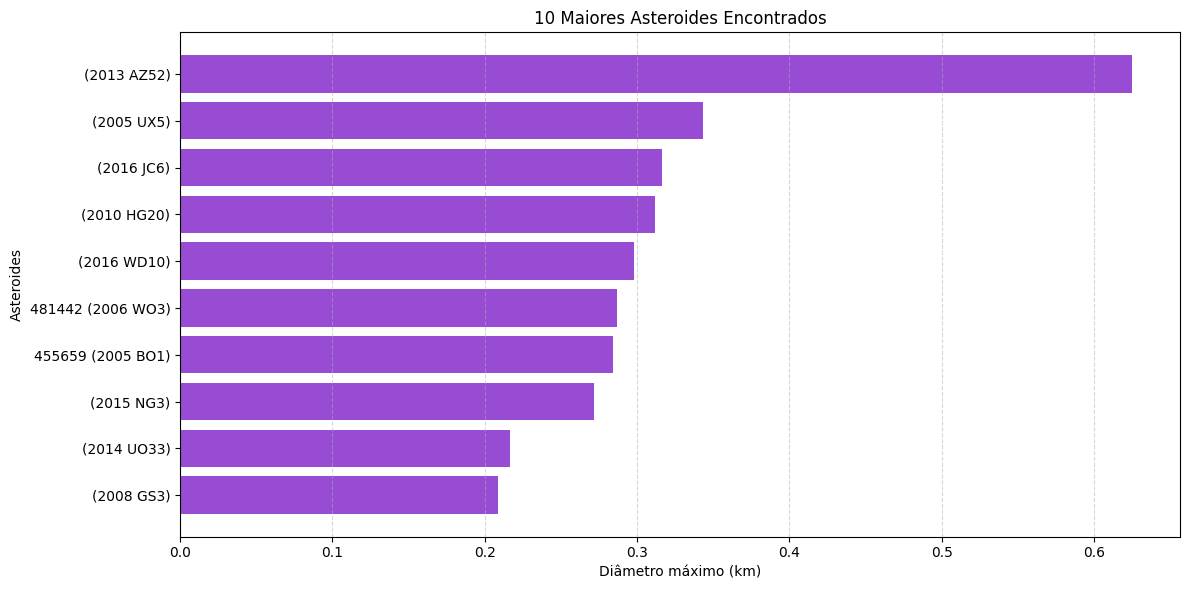

Arquivo relatorio_asteroides.csv criado com sucesso!


In [22]:

# Etapa 3: Gráfico e exportação.

# Selecionando os 10 maiores asteroides
maiores_asteroides = tabela_asteroides.nlargest(
    10,
    "Diâmetro máximo (km)"
)

# Criando o gráfico
plt.figure(figsize=(12, 6))

# Comparando os diâmetros
plt.barh(
    maiores_asteroides["Nome"],
    maiores_asteroides["Diâmetro máximo (km)"],
    color="#984CD4"
)

# Configurando o gráfico
plt.title("10 Maiores Asteroides Encontrados")
plt.xlabel("Diâmetro máximo (km)")
plt.ylabel("Asteroides")
plt.gca().invert_yaxis()
plt.grid(axis="x", linestyle="--", alpha=0.5)

# Ajustando o layout
plt.tight_layout()

# Exibindo o gráfico
plt.show()

# Exportando os dados tratados para CSV
tabela_asteroides.to_csv(
    "relatorio_asteroides.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Arquivo relatorio_asteroides.csv criado com sucesso!")
